In [1]:
import sys
import mne
import pandas as pd
import numpy as np

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("MNE:", mne.__version__)

Python: 3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]
Python executable: c:\Users\ASUS\anaconda3\envs\eeg-alzheimer-detection\python.exe
MNE: 1.13.2


In [3]:
import os

DATASET_PATH = r"D:\EEG Dataset\ds004504"

print(os.path.exists(DATASET_PATH))

True


In [4]:
import os

eeg_file = os.path.join(
    DATASET_PATH,
    "sub-001",
    "eeg",
    "sub-001_task-eyesclosed_eeg.set"
)

print(eeg_file)
print("File exists:", os.path.exists(eeg_file))

D:\EEG Dataset\ds004504\sub-001\eeg\sub-001_task-eyesclosed_eeg.set
File exists: True


In [5]:
file_size = os.path.getsize(eeg_file)

print("File size:", file_size, "bytes")
print("File size:", file_size / (1024 * 1024), "MB")

File size: 24022128 bytes
File size: 22.909286499023438 MB


In [6]:
import mne

raw = mne.io.read_raw_eeglab(
    eeg_file,
    preload=True
)

print(raw)

<RawEEGLAB | sub-001_task-eyesclosed_eeg.set, 19 x 299900 (599.8 s), ~43.5 MiB, data loaded>


In [7]:
print("Number of channels:", len(raw.ch_names))
print("Channels:", raw.ch_names)
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Duration:", raw.times[-1], "seconds")

Number of channels: 19
Channels: ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']
Sampling frequency: 500.0 Hz
Duration: 599.798 seconds


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


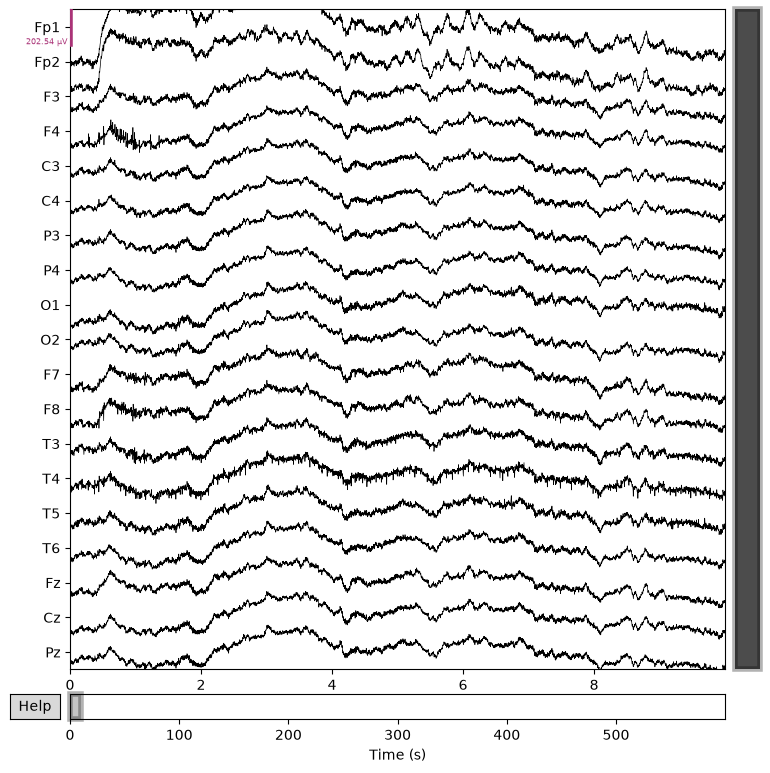

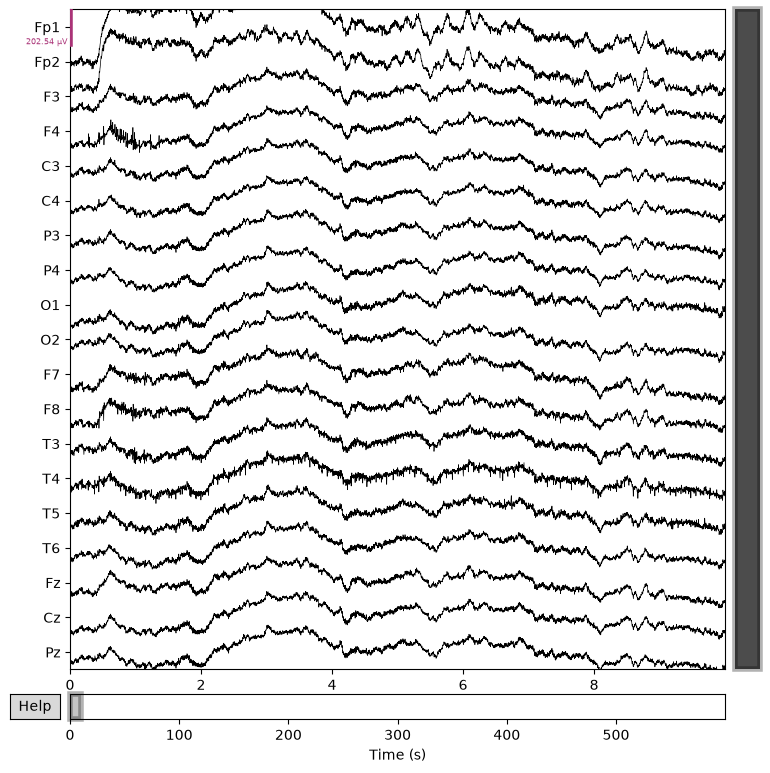

In [11]:
raw.plot(
    duration=10,
    n_channels=19,
    scalings="auto"
)

In [12]:
print("========== EEG INFORMATION ==========")
print("Number of channels:", len(raw.ch_names))
print("Channels:", raw.ch_names)
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Number of samples:", raw.n_times)
print("Duration:", raw.times[-1], "seconds")
print("Recording duration:", raw.times[-1] / 60, "minutes")

========== EEG INFORMATION ==========
Number of channels: 19
Channels: ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']
Sampling frequency: 500.0 Hz
Number of samples: 299900
Duration: 599.798 seconds
Recording duration: 9.996633333333333 minutes


In [13]:
print("\n========== CHANNEL TYPES ==========")
print(raw.get_channel_types())


========== CHANNEL TYPES ==========
['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg']


In [14]:
print("\n========== DATA SHAPE ==========")
print(raw.get_data().shape)


========== DATA SHAPE ==========
(19, 299900)


In [15]:
participants = pd.read_csv(
    os.path.join(DATASET_PATH, "participants.tsv"),
    sep="\t"
)

subject_info = participants[
    participants["participant_id"] == "sub-001"
]

print(subject_info)

  participant_id Gender  Age Group  MMSE
0        sub-001      F   57     A    16
